In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import pearsonr, zscore
import scienceplots
import seaborn as sns
from matplotlib.colors import ListedColormap
colors = {
    "grey":   "#4d4d4d", # neutral line/axis color
}
# NMDA sequential (red)
nmda_cmap = LinearSegmentedColormap.from_list( "nmda_seq", ["#fee0d2", "#f89f84", "#de2d26"], N=256)

In [2]:
# How much excitation / inhibition the nodes receive from other nodes
W_E = np.load('../data/processed/schaefer200_W_E_SC_SLN.npy') # Matrix of SC * SLN
W_I = np.load('../data/processed/schaefer200_W_I_SC_SLN.npy') # Matrix of SC * (1 - SLN)
E_to_source = np.zeros(100)
I_to_source = np.zeros(100)
for index, row in enumerate(W_E): # Each row represents a target, and each column a source
    E_to_source[index] = np.sum(row)
for index, row in enumerate(W_I): # Each row represents a target, and each column a source
    I_to_source[index] = np.sum(row)
E_minus_I_receive = E_to_source - I_to_source # Net excitation
# Area names, remove the 7Networks_LH_ prefix from names
area_names = pd.read_csv('../data/processed/schaefer200_LH_area_names.csv')['Area_name'].tolist()
for index, name in enumerate(area_names):
    area_names[index] = name.replace('7Networks_LH_', '')
    
# Load hierarchy for left hemisphere
hierarchies = pd.read_csv('../data/processed/schaefer200_LH_hierarchy.csv')['Hierarchy_val'].tolist()

W = np.array(pd.read_csv('../data/processed/schaefer200_LH_sc.csv')) # DTI derived normalized structural connectivity matrix
N = W.shape[0] # Number of areas in the network
degree = W.sum(axis=1) # Connectivity degree based on the structural connectivity matrix

# Load NMDA receptor density based on PET
nmda_rd = pd.read_csv('../data/processed/schaefer200_LH_NMDA_rd.csv')['NMDA_rd']

# Persistent areas and delay firing rates across network
persistent_areas = np.load('saved_plots/Figure_3_DF/persistent_areas_G083_alpha134.npy')
delay_fr = np.load('saved_plots/Figure_3_DF/delay_FR_G083_alpha134.npy')

# Build dataframe with all the data
dict_network = {'area_names': area_names, 'hierarchy': hierarchies, 'E_to_source': E_to_source,
                'I_to_source': I_to_source, 'E_minus_I_receive': E_minus_I_receive,
                'nmda_rd': nmda_rd, 'delay_fr': delay_fr, 'degree': degree}
network_connectivity = pd.DataFrame(dict_network)

## Plot long-range input to E vs. I and overlay persistent activity nodes

Number of excitation receivers: 53


/tmp/ipykernel_634431/313194976.py:62: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = ax.legend(loc='best', frameon=False)


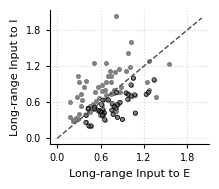

In [3]:
import matplotlib as mpl
mpl.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
})
def excitation_inhibition_receivers(row):
    if row['E_to_source']  - row['I_to_source'] > 0:
        return 'Excitation-Receivers'
    else:
        return 'Inhibition-Receivers'

df_e_vs_i = network_connectivity.copy()
df_e_vs_i['persistent'] = df_e_vs_i['area_names'].isin(persistent_areas)
df_e_vs_i['node_type'] = df_e_vs_i.apply(excitation_inhibition_receivers, axis=1)
print("Number of excitation receivers:", len(df_e_vs_i[df_e_vs_i['node_type'] == 'Excitation-Receivers']))
# Figure 2
fig, ax = plt.subplots(figsize=(2.2, 1.9))
# Boolean masks
mask_exc = df_e_vs_i['E_to_source'] >= df_e_vs_i['I_to_source']
mask_inh = ~mask_exc
# plot excitation-receivers
ax.scatter(
    df_e_vs_i.loc[mask_exc, 'E_to_source'],
    df_e_vs_i.loc[mask_exc, 'I_to_source'],
    c="#7a7a7a",
    s=7,
    alpha=0.9,
    label=''
)
# plot inhibition-receivers
ax.scatter(
    df_e_vs_i.loc[mask_inh, 'E_to_source'],
    df_e_vs_i.loc[mask_inh, 'I_to_source'],
    c='#7a7a7a',
    s=7,
    alpha=0.9,
    label=''
)
ax.plot([0, 2], [0, 2], color=colors['grey'], ls='--', lw=1.0)
ax.set_xlabel('Long-range Input to E', )
ax.set_ylabel('Long-range Input to I', )
ax.grid(linestyle=':', alpha=0.5)
ax = plt.gca()
from matplotlib.ticker import MaxNLocator

ax.minorticks_off()
ax.xaxis.set_major_locator(MaxNLocator(4))
ax.yaxis.set_major_locator(MaxNLocator(4))
ax.grid(which='major', linestyle=':', alpha=0.5)
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
leg = ax.legend(loc='best', frameon=False)
frame = leg.get_frame()
frame.set_edgecolor('grey')

persist = df_e_vs_i[df_e_vs_i['persistent'] == True]
ax.scatter(persist['E_to_source'], persist['I_to_source'],
           facecolors='none', edgecolors='black',
           s=9, linewidths=0.5, label='Persistent')

plt.tight_layout()
plt.savefig('saved_plots/Figure_5/E_to_source_vs_I_to_source.svg', bbox_inches='tight')
plt.show()
plt.close()

Pearson r = 0.842, p = 5.3e-28
Spearman r = 0.953, p = 2.01e-52


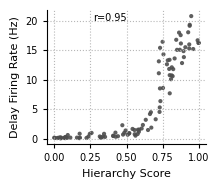

In [4]:
from scipy.stats import spearmanr
# Fit a simple linear trend line
x = network_connectivity['hierarchy']
y = network_connectivity['delay_fr']
r, p = pearsonr(x, y)
print(f"Pearson r = {r:.3f}, p = {p:.3g}")

r_spearman, p_spearman = spearmanr(x, y)
print(f"Spearman r = {r_spearman:.3f}, p = {p_spearman:.3g}")

fig, ax = plt.subplots(figsize=(2.2, 1.9))
ax.scatter(x, y, s=9, alpha=0.9, color=colors['grey'], edgecolor='none')
ax.set_xlabel('Hierarchy Score')
ax.set_ylabel('Delay Firing Rate (Hz)')
ax.grid(linestyle=':', alpha=0.9)
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.tick_params(axis='both', which='major')
ax.tick_params(axis='both', which='minor')
ax.text(
    0.5, 0.98, f"r={r_spearman:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.tight_layout()
plt.savefig('saved_plots/Figure_5/delay_FR_vs_hierarchy.svg', bbox_inches='tight')
plt.show()

Pearson r = -0.160, p = 0.113
Spearman r = -0.218, p = 0.0292


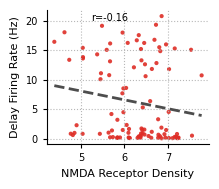

In [5]:
from scipy.stats import spearmanr
# Fit a simple linear trend line
x = network_connectivity['nmda_rd']
y = network_connectivity['delay_fr']
r, p = pearsonr(x, y)
print(f"Pearson r = {r:.3f}, p = {p:.3g}")
r_spearman, p_spearman = spearmanr(x, y)
print(f"Spearman r = {r_spearman:.3f}, p = {p_spearman:.3g}")

fig, ax = plt.subplots(figsize=(2.2, 1.9))
ax.scatter(x, y, s=9, alpha=0.9, color='#de2d26', edgecolor='none')
slope, intercept = np.polyfit(x, y, 1)
y_line = slope * x + intercept
idx = np.argsort(x)
plt.plot(x[idx], y_line[idx],
         color=colors['grey'], linestyle='--', linewidth=2,
         label=f"y = {slope:.2f} x NMDA_rd + ({intercept:.2f})")
ax.set_xlabel('NMDA Receptor Density')
ax.set_ylabel('Delay Firing Rate (Hz)')
ax.grid(linestyle=':', alpha=0.9)
ax = plt.gca()
for spine in ['top','right']:
    ax.spines[spine].set_visible(False)
ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.tick_params(axis='both', which='major')
ax.tick_params(axis='both', which='minor')
ax.text(
    0.5, 0.98, f"r={r:.2f}",
    transform=ax.transAxes,
    va="top",
    ha="right"
)
plt.tight_layout()
plt.savefig('saved_plots/Figure_5/delay_FR_vs_nmda_rd.svg', bbox_inches='tight')
plt.show()

## Combined figure: E/I, hierarchy and NMDA density vs. delay firing rate

Same 18.3 x 4.9 cm size, panel spacing, and Open Sans 8 pt. Run the cells above first.

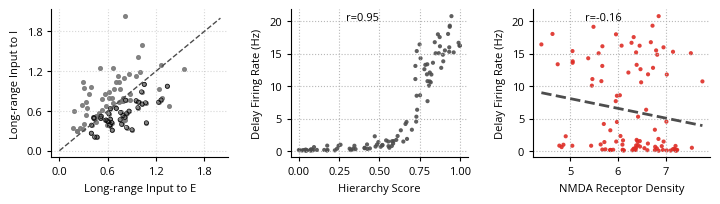

In [6]:
# Combined journal-ready panel: Needs df_e_vs_i (and mask_exc/mask_inh/persist) from the
# "Plot long-range input to E vs. I" cell above, and network_connectivity from the first
# cell, so run those first.
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator
from scipy.stats import spearmanr


fig_params = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.title_fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "pdf.fonttype": 42, 
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

with mpl.rc_context(fig_params):
    fig, axes = plt.subplots(1, 3, figsize=(18.3 / 2.54, 4.9 / 2.54), constrained_layout=True)
    fig.get_layout_engine().set(wspace=0.10, w_pad=0.10)

    # Panel 1: long-range input to E vs. I, persistent nodes highlighted
    # Same data and styling as the "Plot long-range input to E vs. I" cell above
    ax = axes[0]
    ax.scatter(df_e_vs_i.loc[mask_exc, 'E_to_source'], df_e_vs_i.loc[mask_exc, 'I_to_source'],
               c="#7a7a7a", s=7, alpha=0.9)
    ax.scatter(df_e_vs_i.loc[mask_inh, 'E_to_source'], df_e_vs_i.loc[mask_inh, 'I_to_source'],
               c='#7a7a7a', s=7, alpha=0.9)
    ax.plot([0, 2], [0, 2], color=colors['grey'], ls='--', lw=1.0)
    ax.scatter(persist['E_to_source'], persist['I_to_source'],
               facecolors='none', edgecolors='black', s=9, linewidths=0.5, label='Persistent')
    ax.set_xlabel('Long-range Input to E')
    ax.set_ylabel('Long-range Input to I')
    ax.minorticks_off()
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.grid(which='major', linestyle=':', alpha=0.5)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    # leg = ax.legend(loc='best', frameon=False)
    leg.get_frame().set_edgecolor('grey')

    # Panel 2: delay firing rate vs. hierarchy
    # Same data and styling as the "delay_FR_vs_hierarchy" cell above; x/y are recomputed
    # here (rather than reused) because both later cells reassign the same names
    ax = axes[1]
    x = network_connectivity['hierarchy']
    y = network_connectivity['delay_fr']
    r_spearman, p_spearman = spearmanr(x, y)
    ax.scatter(x, y, s=9, alpha=0.9, color=colors['grey'], edgecolor='none')
    ax.set_xlabel('Hierarchy Score')
    ax.set_ylabel('Delay Firing Rate (Hz)')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.grid(linestyle=':', alpha=0.9)
    ax.text(0.5, 0.98, f'r={r_spearman:.2f}', transform=ax.transAxes, va='top', ha='right')

    # Panel 3: delay firing rate vs. NMDA receptor density
    # Same data and styling as the "delay_FR_vs_nmda_rd" cell above
    ax = axes[2]
    x = network_connectivity['nmda_rd']
    y = network_connectivity['delay_fr']
    r, p = pearsonr(x, y)
    slope, intercept = np.polyfit(x, y, 1)
    y_line = slope * x + intercept
    idx = np.argsort(x)
    ax.scatter(x, y, s=9, alpha=0.9, color='#de2d26', edgecolor='none')
    ax.plot(x[idx], y_line[idx], color=colors['grey'], linestyle='--', linewidth=2)
    ax.set_xlabel('NMDA Receptor Density')
    ax.set_ylabel('Delay Firing Rate (Hz)')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.grid(linestyle=':', alpha=0.9)
    ax.text(0.5, 0.98, f'r={r:.2f}', transform=ax.transAxes, va='top', ha='right')

    # No bbox_inches='tight' here, so the saved file keeps the exact 18.3 x 4.9 cm size
    fig.savefig('saved_plots/Figure_5/E_I_hierarchy_nmda_delay_fr_combined.svg')
    fig.savefig('saved_plots/Figure_5/E_I_hierarchy_nmda_delay_fr_combined.pdf')
    plt.show()